# BIOT 6900 · Module 8 Assignment — Single-Cell & Spatial Omics
## Starter notebook: one tumor, two views

This is your **starter**. The plumbing is done for you: the two datasets load in one line each, and the tricky steps (whole-donor sampling, scVI setup, Harmony, the spatial graph) are already written. Your job is to fill in the cells marked **`# TODO`** and to answer the **TODO** questions in the markdown.

- **Part 1 (single-cell):** which cell types express your target?
- **Part 2 (spatial):** where do those cells and that target sit in the tumor?
- **Part 3:** connect the two in your report.

How to use it: run top to bottom, completing each TODO as you reach it. The provided cells must run first for the TODO cells to work. When you are done, **Kernel → Restart & Run All** so the whole notebook executes cleanly, then commit it with your report.

> **Compute:** Part 1's scVI step wants a GPU. Run on Explorer via Open OnDemand (JupyterLab on `courses-gpu`, 1 GPU). Part 2 is CPU-only. See the lab guides for the steps.

### Requirements
Environment: the course `biot6900` / Explorer environment (`scanpy`, `cellxgene-census`, `scvi-tools`, `harmonypy`, `squidpy`). Needs **Python 3.13 or earlier**. If an import fails, run the install cell once and restart the kernel.

In [1]:
# Run once only if an import below fails, then restart the kernel. Python <= 3.13.
# !pip install "cellxgene-census" "scvi-tools" harmonypy squidpy scanpy leidenalg igraph

In [2]:
import scanpy as sc
import squidpy as sq
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

sc.settings.verbosity = 1
sc.settings.set_figure_params(dpi=80, facecolor="white")
try:
    import torch
    GPU = torch.cuda.is_available()
    print("GPU available:", GPU)
except Exception:
    GPU = False
    print("running on CPU")
print("scanpy", sc.__version__, "| squidpy", sq.__version__)

/home/sikkantharbatsha.m/.conda/envs/biot6900/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
/home/sikkantharbatsha.m/.conda/envs/biot6900/lib/python3.11/site-packages/docrep/decorators.py:43: SyntaxWarning: 'n_jobs' is not a valid key!
  doc = func(self, args[0].__doc__, *args[1:], **kwargs)
/home/sikkantharbatsha.m/.conda/envs/biot6900/lib/python3.11/site-packages/docrep/decorators.py:43: SyntaxWarning: 'show_progress_bar' is not a valid key!
  doc = func(self, args[0].__doc__, *args[1:], **kwargs)


GPU available: True
scanpy 1.11.5 | squidpy 1.8.2


/tmp/ipykernel_1373480/1236436484.py:16: FutureWarning: `__version__` is deprecated, use `importlib.metadata.version('scanpy')` instead
  print("scanpy", sc.__version__, "| squidpy", sq.__version__)


In [3]:
# Compatibility patches for scanpy 1.11 with newer scipy / umap-learn
import numpy as np
import scipy.sparse as sp

# Patch 1: newer scipy sparse *arrays* dropped .getnnz(); scanpy's neighbors still calls it
def _getnnz(self, axis=None):
    if axis is None:
        return self.nnz
    m = sp.csr_matrix(self) if axis == 1 else sp.csc_matrix(self)
    return np.diff(m.indptr)

for _cls in (sp.csr_array, sp.csc_array, sp.coo_array):
    if not hasattr(_cls, "getnnz"):
        _cls.getnnz = _getnnz
print("sparse getnnz patch applied")

# Patch 2: umap-learn 0.6 needs C-contiguous kNN arrays; scanpy 1.11 passes array views
import umap.umap_ as _uu
if not getattr(_uu.fuzzy_simplicial_set, "_biot_patched", False):
    _orig_fss = _uu.fuzzy_simplicial_set
    def _fss(*args, **kw):
        for key in ("knn_indices", "knn_dists"):
            if kw.get(key) is not None:
                kw[key] = np.ascontiguousarray(kw[key])
        return _orig_fss(*args, **kw)
    _fss._biot_patched = True
    _uu.fuzzy_simplicial_set = _fss
print("umap contiguity patch applied")

sparse getnnz patch applied
umap contiguity patch applied


In [4]:
import os, subprocess
proxies = {k: v for k, v in os.environ.items() if "proxy" in k.lower()}
print("Proxy variables:", proxies or "none set")

for name, url in [("S3 bucket", "https://cellxgene-census-public-us-west-2.s3.us-west-2.amazonaws.com/cell-census/2025-11-08/soma/"),
                  ("CELLxGENE HTTPS", "https://datasets.cellxgene.cziscience.com/"),
                  ("Google", "https://www.google.com/")]:
    r = subprocess.run(["curl", "-s", "-o", "/dev/null", "-w", "HTTP %{http_code} in %{time_total}s",
                        "--max-time", "30", url], capture_output=True, text=True)
    print(f"{name:16s} -> {r.stdout or r.stderr}")

Proxy variables: {'ftp_proxy': 'http://10.99.0.130:3128', 'https_proxy': 'http://10.99.0.130:3128', 'http_proxy': 'http://10.99.0.130:3128'}
S3 bucket        -> HTTP 404 in 0.288809s
CELLxGENE HTTPS  -> HTTP 403 in 0.374093s
Google           -> HTTP 200 in 0.192781s


---
# PART 1 · Single-cell: which cells express the target

## 1.1 · Pull the breast-cancer data  *(provided)*
This pulls breast-cancer blood/tumor cells from the CZ CELLxGENE Census and samples **10 whole donors**. You do not change anything here.

If the query returns zero cells on your Census version, replace the disease string with the exact one posted on Canvas (Census labels are version-specific).

In [5]:
import os
from urllib.parse import urlparse
import cellxgene_census

_proxy = urlparse(os.environ.get("https_proxy") or os.environ.get("HTTPS_PROXY"))
census = cellxgene_census.open_soma(
    census_version="2025-11-08",                 # pin the release for reproducibility
    tiledb_config={
        "vfs.s3.proxy_host": _proxy.hostname,      # 10.99.0.130 (Explorer's outbound proxy)
        "vfs.s3.proxy_port": _proxy.port,          # 3128
        "vfs.s3.proxy_scheme": _proxy.scheme,      # http
        "vfs.s3.connect_timeout_ms": 60000,
        "vfs.s3.request_timeout_ms": 600000,
        "vfs.s3.connect_max_tries": 10,
    },
)
obs = cellxgene_census.get_obs(
    census, "Homo sapiens",
    value_filter="disease == 'breast cancer' and is_primary_data == True",
    column_names=["soma_joinid", "donor_id", "assay", "cell_type"],
)
print(f"matching cells in the Census: {len(obs):,}")

# Sample whole donors (not scattered cells), so batch-aware steps have enough per donor.
rng = np.random.default_rng(0)
cells_per_donor = 2000
donor_sizes = obs["donor_id"].value_counts()
big_donors = donor_sizes[donor_sizes >= cells_per_donor].index.to_numpy()
donors = rng.choice(big_donors, size=min(10, len(big_donors)), replace=False)
sel = np.concatenate([
    rng.choice(obs.loc[obs["donor_id"] == d, "soma_joinid"].to_numpy(), size=cells_per_donor, replace=False)
    for d in donors
])
adata = cellxgene_census.get_anndata(
    census, "Homo sapiens", obs_coords=np.sort(sel),
    obs_column_names=["donor_id", "assay", "cell_type", "disease", "sex"],
    var_column_names=["feature_id", "feature_name"],
)
census.close()
adata.var_names = adata.var["feature_name"].astype(str)
adata.var_names_make_unique()

def broad_type(ct):
    ct = str(ct).lower()
    if "cd4" in ct or "cd8" in ct or "t cell" in ct or "thymocyte" in ct: return "T"
    if "plasma" in ct or "b cell" in ct: return "B"
    if "natural killer" in ct or "innate lymphoid" in ct: return "NK"
    if "monocyte" in ct: return "Monocyte"
    if "dendritic" in ct: return "DC"
    if "macrophage" in ct: return "Macrophage"
    if "epithel" in ct or "luminal" in ct or "basal" in ct or "carcinoma" in ct or "tumor" in ct: return "Epithelial/Tumor"
    if "fibroblast" in ct or "stromal" in ct: return "Fibroblast"
    if "endothel" in ct: return "Endothelial"
    return "Other"
adata.obs["cell_type_broad"] = adata.obs["cell_type"].map(broad_type).astype("category")
print(f"\n{adata.n_obs:,} cells from {len(donors)} donors")
print(adata.obs["cell_type_broad"].value_counts())

matching cells in the Census: 1,101,430


/home/sikkantharbatsha.m/.conda/envs/biot6900/lib/python3.11/functools.py:909: ImplicitModificationWarning: Transforming to str index.
  return dispatch(args[0].__class__)(*args, **kw)
/home/sikkantharbatsha.m/.conda/envs/biot6900/lib/python3.11/functools.py:909: ImplicitModificationWarning: Transforming to str index.
  return dispatch(args[0].__class__)(*args, **kw)



20,000 cells from 10 donors
cell_type_broad
T                   12121
Other                3125
Endothelial          1466
Macrophage           1260
Fibroblast           1118
B                     586
Epithelial/Tumor      152
Monocyte               73
NK                     61
DC                     38
Name: count, dtype: int64


/tmp/ipykernel_1373480/412929585.py:41: UserWarning: Suffix used (-[0-9]+) to deduplicate index values may make index values difficult to interpret. There values with a similar suffixes in the index. Consider using a different delimiter by passing `join={delimiter}`. Example key collisions generated by the make_index_unique algorithm: ['SNORD115-1', 'SNORD115-2', 'SNORD115-3', 'SNORD115-4', 'SNORD115-5']
  adata.var_names_make_unique()


In [6]:
# Fix broad labels: the starter's substring match sends "malignant cell" and
# "myofibroblast cell" to "T" because both contain the letters "t cell".
import re
def fix_broad(ct, broad):
    c = ct.lower()
    if any(k in c for k in ["malignant", "epithelial", "luminal", "cancer"]):
        return "Epithelial/Tumor"
    if "myofibroblast" in c:
        return "Fibroblast"
    if re.search(r"\bmast cell\b", c):
        return "Mast cell"
    if broad == "T" and not re.search(r"\bt cell\b", c):
        return "Other"
    return broad

before = adata.obs["cell_type_broad"].value_counts()
adata.obs["cell_type_broad"] = pd.Categorical(
    [fix_broad(c, b) for c, b in zip(adata.obs["cell_type"].astype(str),
                                     adata.obs["cell_type_broad"].astype(str))])
print(pd.DataFrame({"before": before, "after": adata.obs["cell_type_broad"].value_counts()}).fillna(0).astype(int))

                  before  after
cell_type_broad                
B                    586    586
DC                    38     38
Endothelial         1466   1466
Epithelial/Tumor     152   9768
Fibroblast          1118   1144
Macrophage          1260   1260
Mast cell              0     17
Monocyte              73     73
NK                    61     61
Other               3125   3125
T                  12121   2462


In [7]:
print(adata.obs.loc[adata.obs["cell_type_broad"] == "Other", "cell_type"].value_counts().head(15))
print("\nAssays:\n", adata.obs["assay"].value_counts())
print("\nCells per donor:\n", adata.obs["donor_id"].value_counts())
print("\nERBB2 present:", "ERBB2" in adata.var_names)

cell_type
hepatocyte                                      2606
blood vessel smooth muscle cell                  139
cell of skeletal muscle                          135
hepatic stellate cell                            110
mononuclear phagocyte                             58
T follicular helper cell                          49
neuron                                            16
vascular associated smooth muscle cell            10
pericyte                                           2
mucosa-associated lymphoid tissue macrophage       0
motor neuron                                       0
monocyte-derived dendritic cell                    0
monocyte                                           0
migratory enteric neural crest cell                0
midzonal region hepatocyte                         0
Name: count, dtype: int64

Assays:
 assay
10x 3' v3                                          13922
10x 3' v2                                           4078
10x 5' v2                              

## 1.2 · Standard pipeline  *(provided)*
QC, normalize, batch-aware highly variable genes, PCA. The raw counts are kept for scVI and for marker plots.

In [8]:
# Safe to re-run: always restart from raw counts
if "counts" not in adata.layers:
    sc.pp.filter_genes(adata, min_cells=3)
    sc.pp.filter_cells(adata, min_genes=200)
    adata.layers["counts"] = adata.X.copy()
adata.X = adata.layers["counts"].copy()

adata.var["mt"] = adata.var_names.str.startswith("MT-")
sc.pp.calculate_qc_metrics(adata, qc_vars=["mt"], percent_top=None, log1p=False, inplace=True)
adata = adata[(adata.obs.n_genes_by_counts < 6000) & (adata.obs.pct_counts_mt < 15)].copy()
sc.pp.filter_genes(adata, min_cells=10)          # drop near-empty genes that destabilise per-donor fits

sc.pp.normalize_total(adata, target_sum=1e4)
sc.pp.log1p(adata)
adata.raw = adata

try:
    sc.pp.highly_variable_genes(adata, n_top_genes=2000, flavor="seurat_v3",
                                layer="counts", batch_key="donor_id", span=0.5)
    hvg_method = "seurat_v3 (counts, batch_key=donor_id, span=0.5)"
except ValueError as e:
    print("seurat_v3 failed for a donor:", e, "-> falling back to batch-aware 'seurat' flavor")
    sc.pp.highly_variable_genes(adata, n_top_genes=2000, flavor="seurat", batch_key="donor_id")
    hvg_method = "seurat (log-normalized, batch_key=donor_id)"
print("HVG method:", hvg_method, "| HVGs:", int(adata.var.highly_variable.sum()))

adata = adata[:, adata.var.highly_variable].copy()
sc.pp.scale(adata, max_value=10)
sc.tl.pca(adata, svd_solver="arpack")
print("cells after QC:", adata.n_obs, "| genes kept:", adata.n_vars)

HVG method: seurat_v3 (counts, batch_key=donor_id, span=0.5) | HVGs: 2000


/home/sikkantharbatsha.m/.conda/envs/biot6900/lib/python3.11/functools.py:909: UserWarning: zero-centering a sparse array/matrix densifies it.
  return dispatch(args[0].__class__)(*args, **kw)


cells after QC: 18388 | genes kept: 2000


## 1.3 · The batch problem
The unintegrated embedding is computed for you. **TODO:** plot it and say what you see.

In [9]:
sc.pp.neighbors(adata, n_neighbors=15, n_pcs=30, use_rep="X_pca")
sc.tl.umap(adata)
adata.obsm["X_umap_unint"] = adata.obsm["X_umap"].copy()

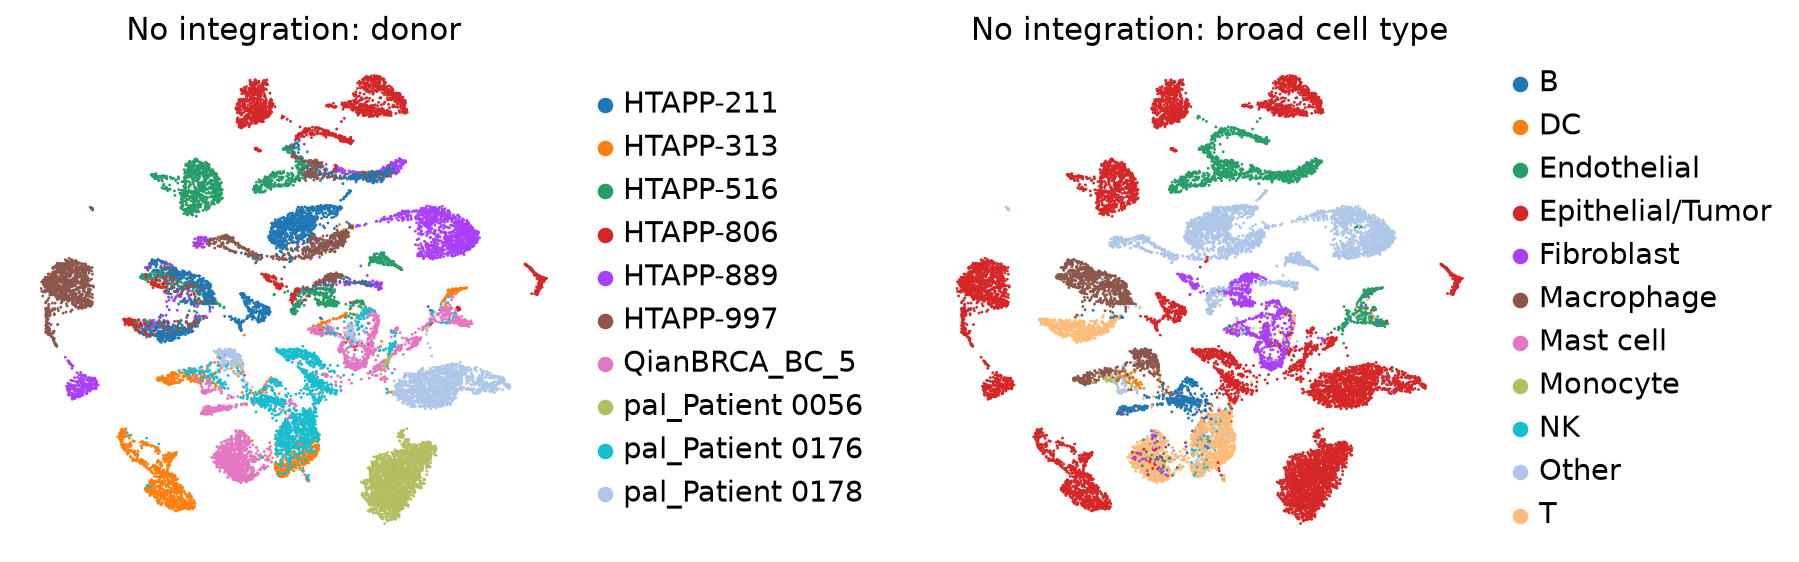

30 unintegrated clusters; 17 are >80% from a single donor


,n_cells,top_donor_fraction,top_donor
leiden_unint,,,
13,1927,1.00,pal_Patient 0056
11,235,1.00,HTAPP-211
10,864,1.00,QianBRCA_BC_5
18,18,1.00,HTAPP-806
27,150,1.00,HTAPP-806
29,16,1.00,HTAPP-997
23,248,1.00,HTAPP-889
24,761,1.00,HTAPP-516
25,132,1.00,HTAPP-516


In [10]:
sc.pl.embedding(adata, basis="umap_unint", color=["donor_id", "cell_type_broad"],
                wspace=0.5, frameon=False,
                title=["No integration: donor", "No integration: broad cell type"])

sc.tl.leiden(adata, resolution=0.5, key_added="leiden_unint",
             flavor="igraph", n_iterations=2, directed=False)
ct = pd.crosstab(adata.obs["leiden_unint"], adata.obs["donor_id"].astype(str))
top_donor_frac = (ct.max(axis=1) / ct.sum(axis=1)).round(2)
summary = pd.DataFrame({"n_cells": ct.sum(axis=1), "top_donor_fraction": top_donor_frac,
                        "top_donor": ct.idxmax(axis=1)}).sort_values("top_donor_fraction", ascending=False)
print(f"{len(ct)} unintegrated clusters; {(top_donor_frac > 0.8).sum()} are >80% from a single donor")
display(summary)

**TODO (interpretation):** In one or two sentences, what do these two plots show? Is the data organized by donor or by biology?

*Your answer here.*

In [11]:
#Without integration, the map is organized mainly by donor rather than biology. In the donor-colored UMAP, most islands are a single color, and in the cell-type UMAP, the same broad cell type (for example T cells, macrophages, fibroblasts and the hepatocyte-rich “Other” group) is split across several separate donor-specific islands instead of forming one cluster per type. Quantitatively, 17 of the 30 unintegrated Leiden clusters are more than 80% from a single donor, and 13 are 100% from one donor (e.g. cluster 13: 1,927 cells, all pal_Patient 0056). Only a few mostly-T-cell clusters mix donors (lowest top-donor fraction 0.37–0.52). Part of this separation is real biology, because the donors were sampled from different tumor sites (hepatocytes appear only in liver-metastasis donors) and were profiled with three different 10x chemistries. But because shared cell types still separate by donor, technical batch effects dominate, and integration is needed before cell types can be compared across donors.

## 1.4 · Integrate with scVI  *(provided, GPU step)*

In [12]:
import scvi
scvi.model.SCVI.setup_anndata(adata, layer="counts", batch_key="donor_id")
vae = scvi.model.SCVI(adata, n_latent=30)
vae.train(max_epochs=(200 if GPU else 60), accelerator=("gpu" if GPU else "cpu"))
adata.obsm["X_scVI"] = vae.get_latent_representation()
sc.pp.neighbors(adata, n_neighbors=15, use_rep="X_scVI")
sc.tl.umap(adata)
adata.obsm["X_umap_scvi"] = adata.obsm["X_umap"].copy()
print("scVI done")

/home/sikkantharbatsha.m/.conda/envs/biot6900/lib/python3.11/site-packages/lightning/fabric/plugins/environments/slurm.py:204: The `srun` command is available on your system but is not used. HINT: If your intention is to run Lightning on SLURM, prepend your python command with `srun` like so: srun python /home/sikkantharbatsha.m/.conda/envs/biot6900/lib/py ...
GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
/home/sikkantharbatsha.m/.conda/envs/biot6900/lib/python3.11/site-packages/lightning/fabric/plugins/environments/slurm.py:204: The `srun` command is available on your system but is not used. HINT: If your intention is to run Lightning on SLURM, prepend your python command with `srun` like so: srun python /home/sikkantharbatsh

Epoch 200/200: 100%|██████████| 200/200 [07:29<00:00,  2.12s/it, v_num=1, train_loss=509]

`Trainer.fit` stopped: `max_epochs=200` reached.


Epoch 200/200: 100%|██████████| 200/200 [07:29<00:00,  2.25s/it, v_num=1, train_loss=509]
scVI done


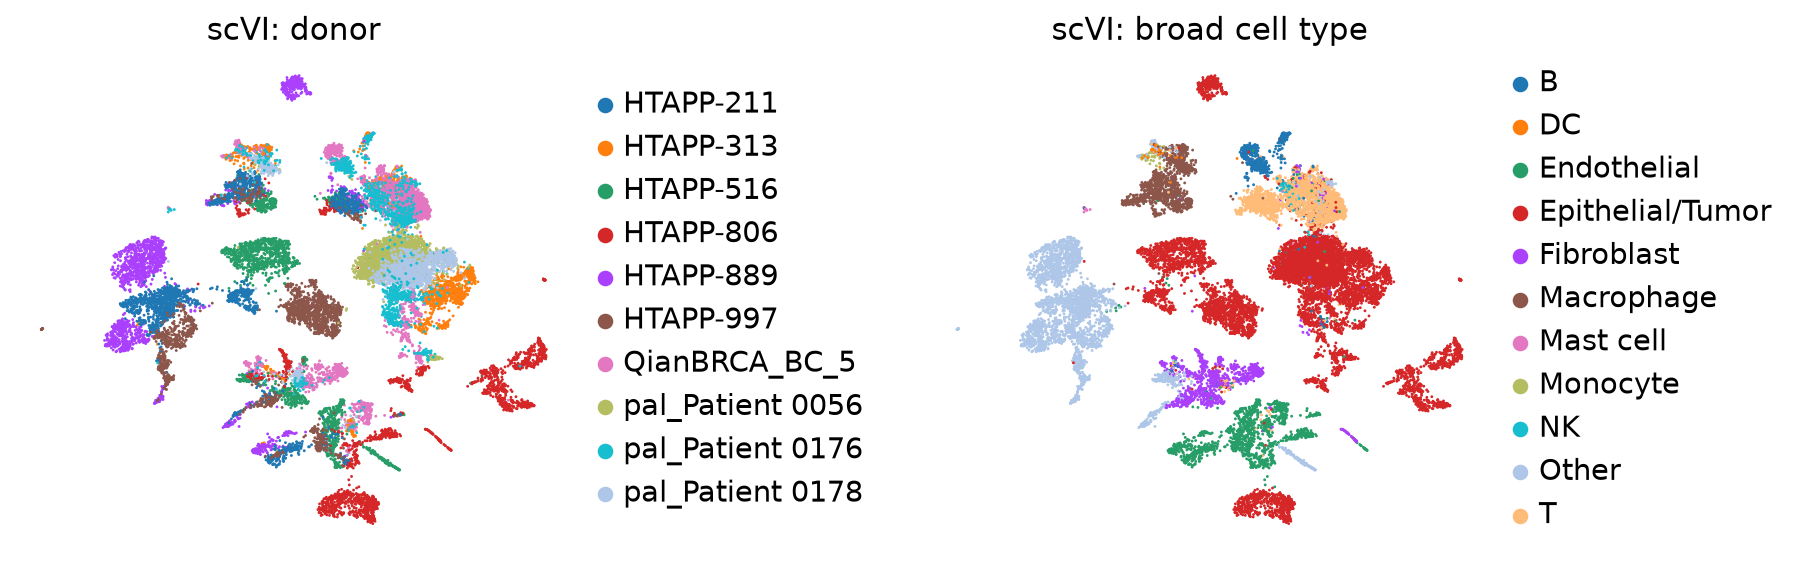

scVI: 27 clusters; 13 are >80% from a single donor (unintegrated: 17 of 30)


In [13]:
sc.pl.embedding(adata, basis="umap_scvi", color=["donor_id", "cell_type_broad"],
                wspace=0.5, frameon=False,
                title=["scVI: donor", "scVI: broad cell type"])

sc.tl.leiden(adata, resolution=0.5, key_added="leiden_scvi",
             flavor="igraph", n_iterations=2, directed=False)
ct = pd.crosstab(adata.obs["leiden_scvi"], adata.obs["donor_id"].astype(str))
top = (ct.max(axis=1) / ct.sum(axis=1)).round(2)
print(f"scVI: {len(ct)} clusters; {(top > 0.8).sum()} are >80% from a single donor "
      f"(unintegrated: 17 of 30)")

## 1.5 · Harmony, a fair baseline  *(provided)*

In [14]:
import harmonypy
ho = harmonypy.run_harmony(adata.obsm["X_pca"].astype(np.float64), adata.obs, "donor_id")
Z = np.asarray(ho.Z_corr)
adata.obsm["X_pca_harmony"] = Z if Z.shape[0] == adata.n_obs else Z.T
print("Harmony done")

2026-11-19 07:13:28,855 - harmonypy - INFO - Running Harmony
2026-11-19 07:13:28,856 - harmonypy - INFO -   Parameters:
2026-11-19 07:13:28,857 - harmonypy - INFO -     max_iter_harmony: 10
2026-11-19 07:13:28,857 - harmonypy - INFO -     max_iter_kmeans: 4
2026-11-19 07:13:28,858 - harmonypy - INFO -     epsilon_cluster: 0.001
2026-11-19 07:13:28,859 - harmonypy - INFO -     epsilon_harmony: 0.01
2026-11-19 07:13:28,860 - harmonypy - INFO -     nclust: 100
2026-11-19 07:13:28,860 - harmonypy - INFO -     block_size: 0.05
2026-11-19 07:13:28,862 - harmonypy - INFO -     lamb: dynamic (alpha=0.2)
2026-11-19 07:13:28,863 - harmonypy - INFO -     theta: [2. 2. 2. 2. 2. 2. 2. 2. 2. 2.]
2026-11-19 07:13:28,864 - harmonypy - INFO -     sigma: [0.1 0.1 0.1 0.1 0.1]...
2026-11-19 07:13:28,865 - harmonypy - INFO -     verbose: True
2026-11-19 07:13:28,866 - harmonypy - INFO -     random_state: 0
2026-11-19 07:13:28,867 - harmonypy - INFO -   Data: 50 PCs × 18388 cells
2026-11-19 07:13:28,867 - 

Harmony done


## 1.6 · Judge the fix
**TODO:** compute how well each method (no integration, Harmony, scVI) mixes donors and preserves cell types, then decide which you would use.

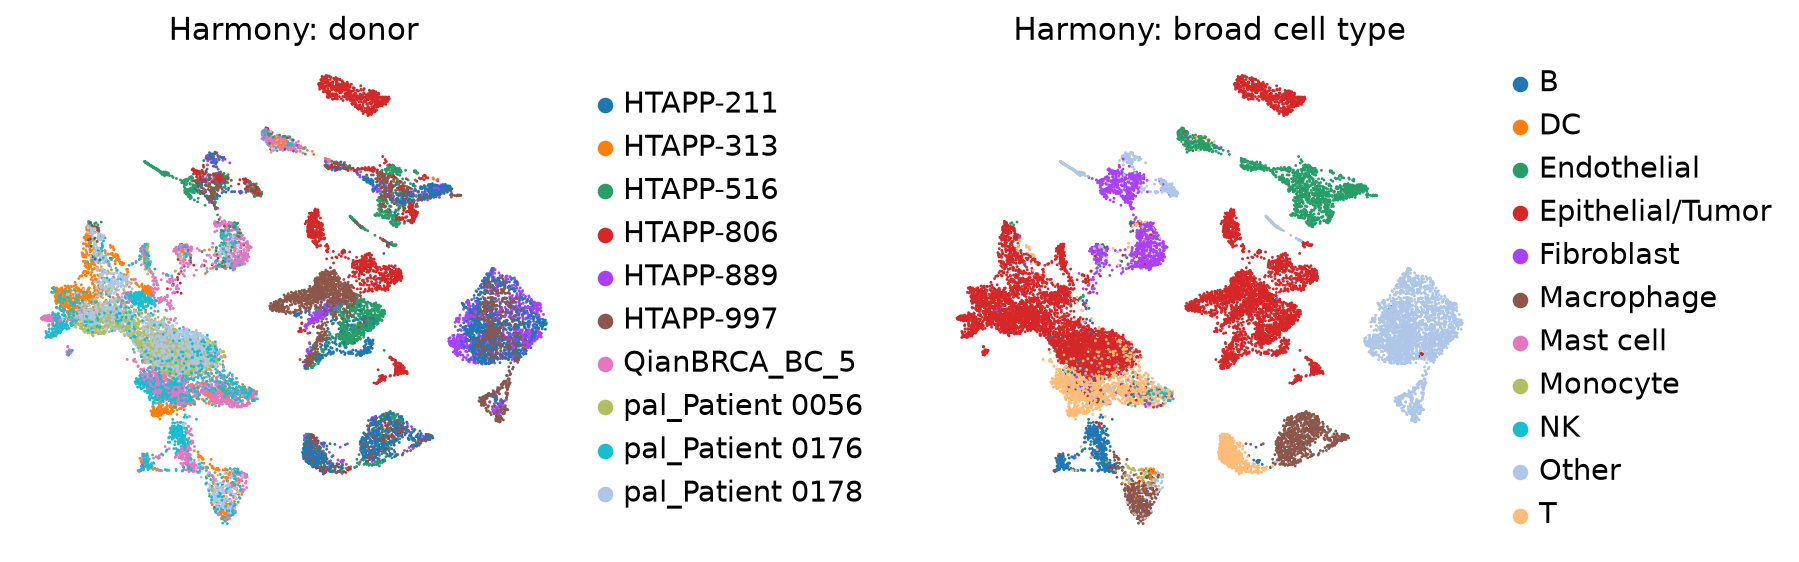

No integration 0.09 -0.03
Harmony -0.081 0.002
scVI -0.059 0.042


,batch_silhouette (lower=better),celltype_silhouette (higher=better)
method,,
No integration,0.090,-0.030
Harmony,-0.081,0.002
scVI,-0.059,0.042


In [15]:
from sklearn.metrics import silhouette_score

# Make sure Harmony is plotted too (rubric: "scVI and Harmony both run and plotted")
if "X_umap_harmony" not in adata.obsm:
    sc.pp.neighbors(adata, n_neighbors=15, use_rep="X_pca_harmony", key_added="nn_harmony")
    sc.tl.umap(adata, neighbors_key="nn_harmony")
    adata.obsm["X_umap_harmony"] = adata.obsm["X_umap"].copy()
sc.pl.embedding(adata, basis="umap_harmony", color=["donor_id", "cell_type_broad"],
                wspace=0.5, frameon=False, title=["Harmony: donor", "Harmony: broad cell type"])

# Batch mixing (silhouette by donor, lower = better mixed) vs biology preservation
# (silhouette by cell type, higher = cell types better separated)
rng_s = np.random.default_rng(0)
idx = rng_s.choice(adata.n_obs, size=min(5000, adata.n_obs), replace=False)
reps = {"No integration": "X_pca", "Harmony": "X_pca_harmony", "scVI": "X_scVI"}
rows = []
for name, key in reps.items():
    emb = adata.obsm[key][idx]
    batch = silhouette_score(emb, adata.obs["donor_id"].values[idx])
    bio = silhouette_score(emb, adata.obs["cell_type_broad"].values[idx])
    rows.append({"method": name, "batch_silhouette (lower=better)": round(batch, 3),
                 "celltype_silhouette (higher=better)": round(bio, 3)})
    print(name, round(batch, 3), round(bio, 3))
scores = pd.DataFrame(rows).set_index("method")
display(scores)

**TODO (interpretation):** Which method would you use, and why? Does the expensive deep-learning method clearly beat the simple one?

*Your answer here. I would use scVI. Both methods removed the donor batch effect: the donor silhouette fell from +0.090 without integration to −0.081 (Harmony) and −0.059 (scVI), where values at or below zero mean donors are well mixed. But scVI preserved biology much better: the cell-type silhouette rose from −0.030 to 0.042 with scVI, compared with only 0.002 with Harmony. Harmony’s slightly stronger mixing therefore came with some loss of cell-type structure, a mild over-correction, while scVI, which models raw counts and the donor effect directly, kept cell types distinct. So the expensive deep-learning method does win here, but only modestly: all silhouettes are small, they come from one 5,000-cell subsample and one seed, and the broad labels limit how much structure the score can reward. Harmony remains a fast, reasonable alternative (seconds on a CPU versus GPU training).

## 1.7 · Annotate and confirm with markers
The broad cell types are already assigned. **TODO:** plot the labeled map and a few canonical markers to confirm it.

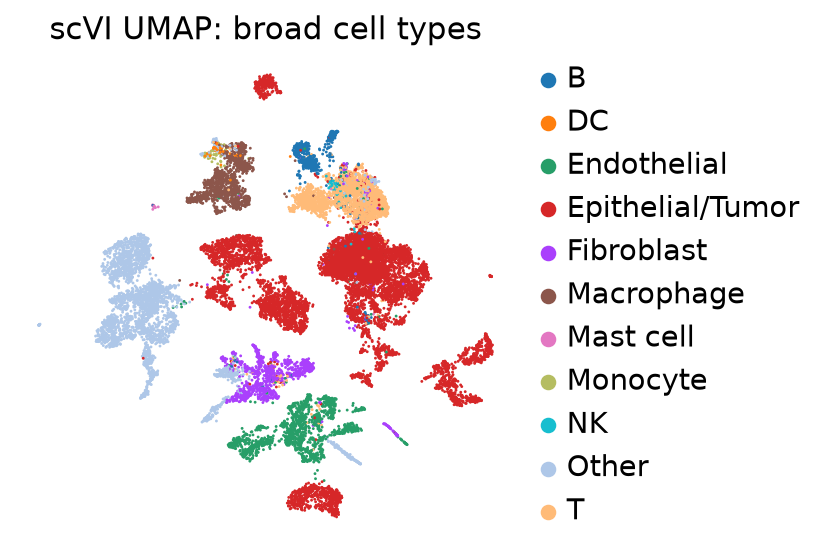

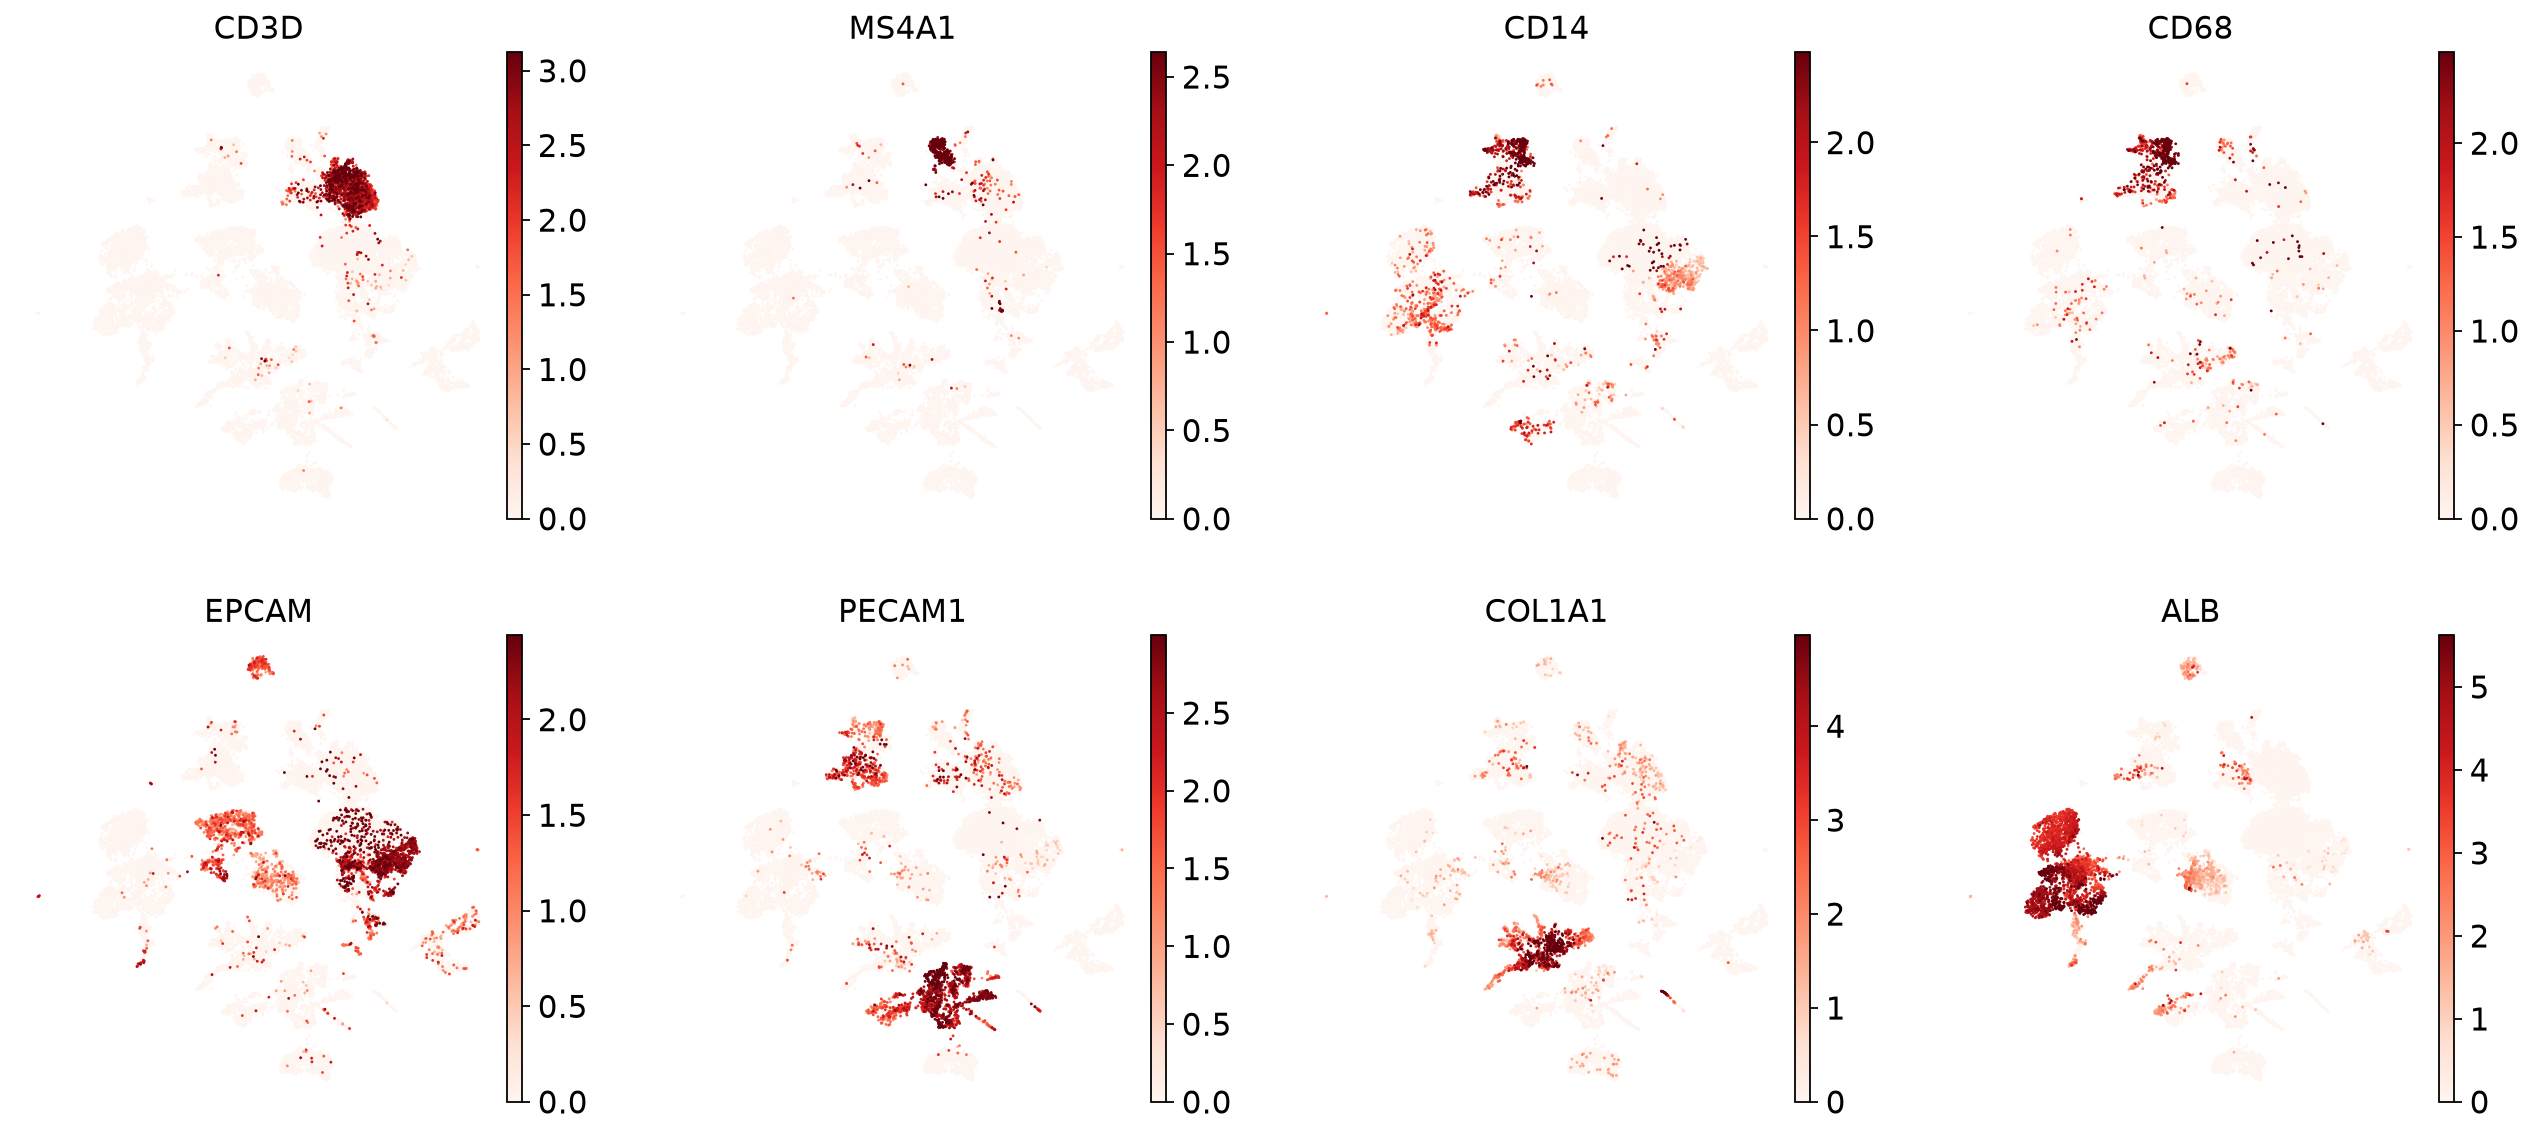

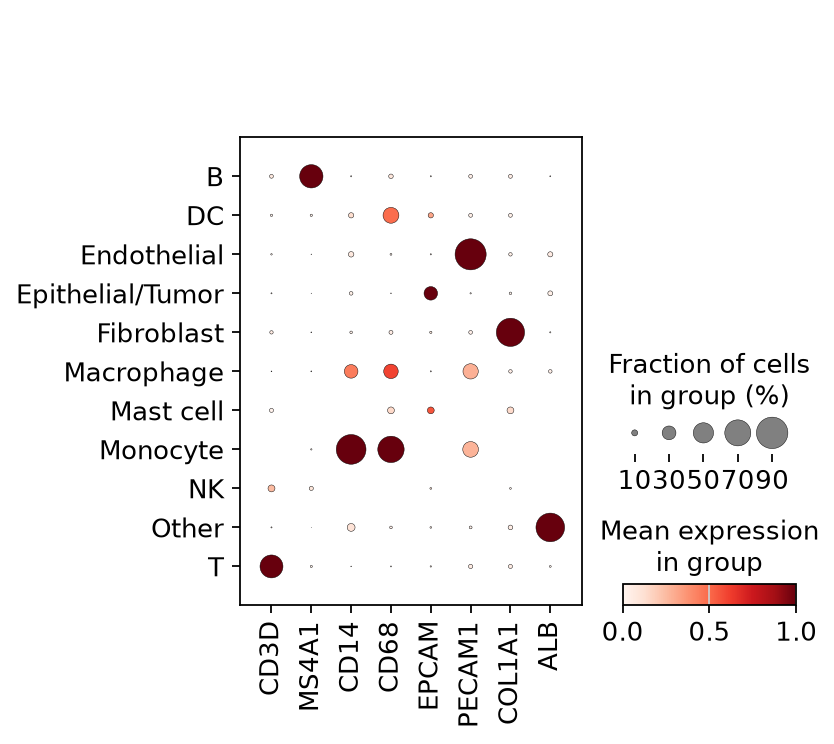

In [16]:
sc.pl.embedding(adata, basis="umap_scvi", color="cell_type_broad", frameon=False,
                title="scVI UMAP: broad cell types")

markers = [g for g in ["CD3D", "MS4A1", "CD14", "CD68", "EPCAM", "PECAM1", "COL1A1", "ALB"]
           if g in adata.raw.var_names]
sc.pl.embedding(adata, basis="umap_scvi", color=markers, use_raw=True, ncols=4,
                frameon=False, cmap="Reds", vmax="p99")

# Quantitative confirmation: each marker should peak in its expected cell type
sc.pl.dotplot(adata, markers, groupby="cell_type_broad", use_raw=True, standard_scale="var")

In [17]:
print(adata.obs.loc[adata.obs["cell_type_broad"] == "T", "cell_type"].value_counts().head(10))

cell_type
T cell                                                                      1688
naive T cell                                                                 174
effector memory CD8-positive, alpha-beta T cell                              150
mature NK T cell                                                              72
CD8-positive, alpha-beta regulatory T cell                                    68
effector memory CD4-positive, alpha-beta T cell                               67
CD4-positive, CD25-positive, CCR4-positive, alpha-beta regulatory T cell      67
exhausted T cell                                                              17
cycling T cell                                                                10
capillary endothelial cell                                                     0
Name: count, dtype: int64


## 1.8 · Locate your target in the cell types
**TODO:** choose your target gene, plot it, and identify which cell type(s) express it.

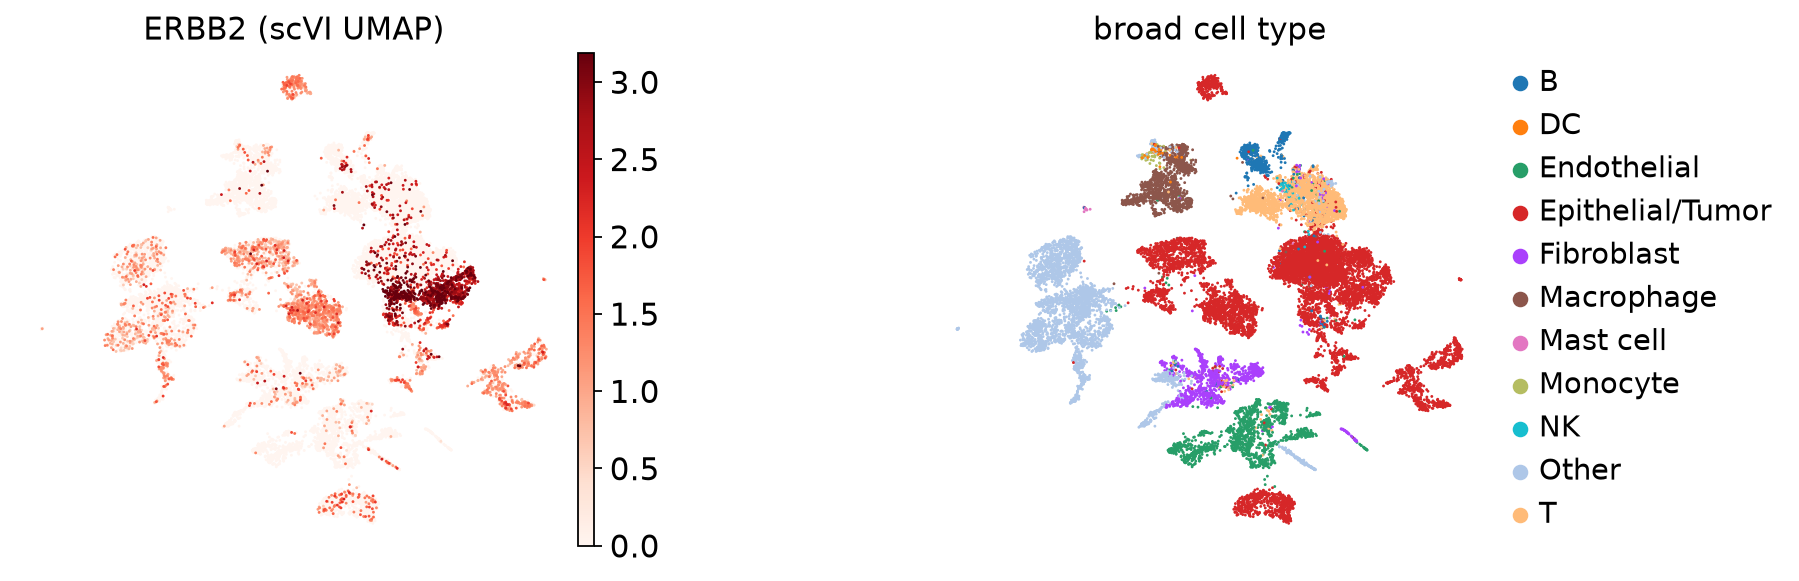

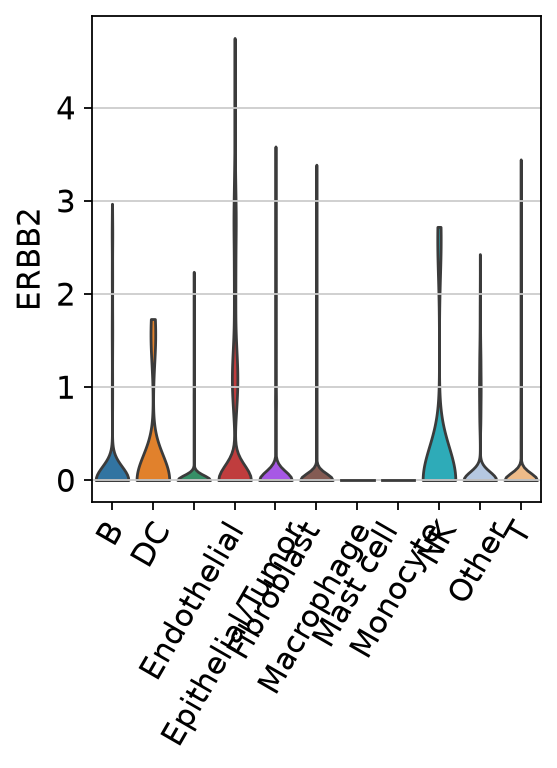

,n_cells,mean_log_expr,pct_expressing
cell_type_broad,,,
Epithelial/Tumor,8678,0.634,36.356
NK,50,0.258,10.000
DC,36,0.218,13.889
Other,2976,0.192,17.070
B,529,0.134,7.183
Fibroblast,1096,0.114,9.580
T,2313,0.055,2.508
Macrophage,1189,0.048,3.028
Endothelial,1431,0.042,3.843


,n_tumor_cells,mean_log_expr,pct_expressing
donor_id,,,
HTAPP-313,776,2.420,92.912
pal_Patient 0176,563,1.860,66.430
HTAPP-997,1021,0.845,73.359
HTAPP-889,248,0.838,68.145
HTAPP-516,758,0.520,50.792
QianBRCA_BC_5,271,0.449,38.007
HTAPP-806,1421,0.419,33.638
HTAPP-211,241,0.215,17.842
pal_Patient 0056,1963,0.125,4.840


In [18]:
TARGET = "ERBB2"   # HER2: on the course shortlist; the Visium section in Part 2 is HER2-positive
assert TARGET in adata.raw.var_names, f"{TARGET} not found"

sc.pl.embedding(adata, basis="umap_scvi", color=[TARGET, "cell_type_broad"], use_raw=True,
                cmap="Reds", vmax="p99", wspace=0.5, frameon=False,
                title=[f"{TARGET} (scVI UMAP)", "broad cell type"])
sc.pl.violin(adata, TARGET, groupby="cell_type_broad", use_raw=True, rotation=60, stripplot=False)

# Which cell types express it? mean expression + % of cells expressing, per type
x = adata.raw[:, TARGET].X
x = x.toarray().ravel() if hasattr(x, "toarray") else np.asarray(x).ravel()
adata.obs[f"{TARGET}_expr"] = x
target_tab = (adata.obs.groupby("cell_type_broad", observed=True)[f"{TARGET}_expr"]
              .agg(n_cells="size", mean_log_expr="mean", pct_expressing=lambda v: 100 * (v > 0).mean())
              .sort_values("mean_log_expr", ascending=False).round(3))
display(target_tab)

# HER2 is amplified only in some patients: compare tumor cells across donors
tum = adata.obs[adata.obs["cell_type_broad"] == "Epithelial/Tumor"]
donor_tab = (tum.groupby(tum["donor_id"].astype(str))[f"{TARGET}_expr"]
             .agg(n_tumor_cells="size", mean_log_expr="mean", pct_expressing=lambda v: 100 * (v > 0).mean())
             .sort_values("mean_log_expr", ascending=False).round(3))
display(donor_tab)

**TODO (interpretation):** Which cell type(s) express your target? 

*Your answer here.*

---ERBB2 (HER2) is expressed mainly by the epithelial/tumor cells. They have by far the highest mean expression (0.634 log-normalized) and the highest fraction of expressing cells (36.4% of 8,678 cells). Every non-epithelial compartment is low: fibroblasts 0.114, T cells 0.055, macrophages 0.048 and endothelial cells 0.042, each with ≤10% of cells expressing. The small signals in NK cells (n = 50) and DCs (n = 36) come from very few cells and most likely reflect ambient RNA or doublets rather than real expression. On the scVI UMAP the darkest ERBB2 signal sits inside the tumor clusters, not the immune or stromal ones. Expression is also strongly patient-specific. Tumor cells from HTAPP-313 (mean 2.42; 92.9% expressing) and pal_Patient 0176 (1.86; 66.4%) are ERBB2-high, consistent with HER2-amplified tumors, while tumor cells from pal_Patient 0056 (0.125; 4.8%) and pal_Patient 0178 (0.065; 2.7%) barely express it, consistent with HER2-negative disease. So ERBB2 is a tumor-cell target, but only in a subset of patients, which is why HER2 therapy depends on testing each patient’s tumor. This conclusion depended on correcting the starter’s labels: before the fix, 8,526 “malignant cell” were mislabeled as T cells, which would have wrongly placed ERBB2 in the T-cell compartment.
# PART 2 · Spatial: where those cells sit in the tumor

## 2.1 · Load the provided Visium section  *(provided)*
A real 10x human breast-cancer Visium section. Downloads once on the first run.

In [19]:
spatial = sc.datasets.visium_sge(sample_id="V1_Breast_Cancer_Block_A_Section_1")
spatial.var_names_make_unique()
print(spatial)
print("spots x genes:", spatial.shape)

/tmp/ipykernel_1373480/520941202.py:1: FutureWarning: Use `squidpy.datasets.visium` instead.
  spatial = sc.datasets.visium_sge(sample_id="V1_Breast_Cancer_Block_A_Section_1")
/home/sikkantharbatsha.m/.conda/envs/biot6900/lib/python3.11/site-packages/scanpy/datasets/_datasets.py:555: FutureWarning: Use `squidpy.read.visium` instead.
  return read_visium(sample_dir, source_image_path=source_image_path)
/home/sikkantharbatsha.m/.conda/envs/biot6900/lib/python3.11/site-packages/anndata/_core/anndata.py:1884: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")


AnnData object with n_obs × n_vars = 3798 × 36601
    obs: 'in_tissue', 'array_row', 'array_col'
    var: 'gene_ids', 'feature_types', 'genome'
    uns: 'spatial'
    obsm: 'spatial'
spots x genes: (3798, 36601)


/home/sikkantharbatsha.m/.conda/envs/biot6900/lib/python3.11/site-packages/anndata/_core/anndata.py:1884: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")


## 2.2 · Pipeline and clustering  *(provided)*

In [20]:
spatial.var["mt"] = spatial.var_names.str.startswith("MT-")
sc.pp.calculate_qc_metrics(spatial, qc_vars=["mt"], inplace=True)
sc.pp.filter_cells(spatial, min_counts=500)
spatial.layers["counts"] = spatial.X.copy()
sc.pp.normalize_total(spatial, target_sum=1e4)
sc.pp.log1p(spatial)
spatial.raw = spatial
sc.pp.highly_variable_genes(spatial, n_top_genes=2000)
sc.pp.pca(spatial)
sc.pp.neighbors(spatial)
sc.tl.leiden(spatial, resolution=0.6, key_added="cluster")
print("spatial domains found:", spatial.obs["cluster"].nunique())

/tmp/ipykernel_1373480/4117200164.py:11: FutureWarning: In the future, the default backend for leiden will be igraph instead of leidenalg.

 To achieve the future defaults please pass: flavor="igraph" and n_iterations=2.  directed must also be False to work with igraph's implementation.
  sc.tl.leiden(spatial, resolution=0.6, key_added="cluster")


spatial domains found: 9


## 2.3 · Spatial domains on the tissue
**TODO:** draw the clusters back onto the tissue and relate them to tumor, stroma, and immune regions.

/tmp/ipykernel_1373480/4133554473.py:2: FutureWarning: Use `squidpy.pl.spatial_scatter` instead.
  sc.pl.spatial(spatial, img_key="hires", title="H&E: V1_Breast_Cancer_Block_A_Section_1")


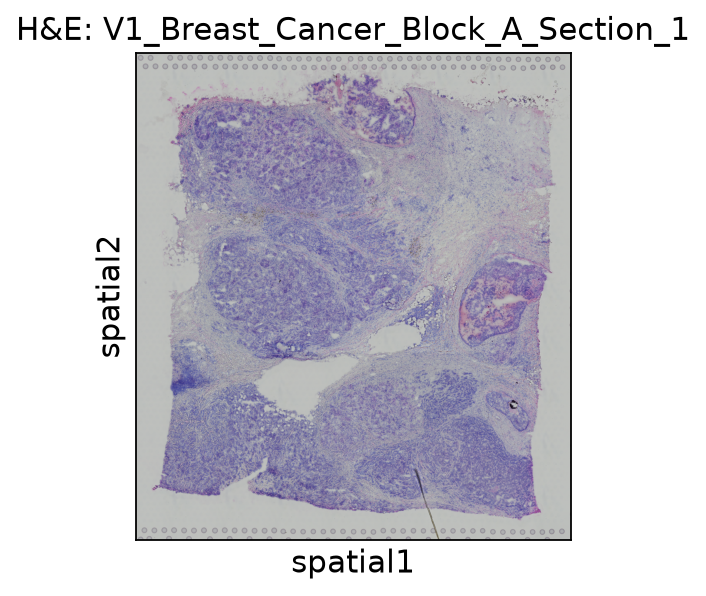

/tmp/ipykernel_1373480/4133554473.py:3: FutureWarning: Use `squidpy.pl.spatial_scatter` instead.
  sc.pl.spatial(spatial, color="cluster", img_key="hires", alpha=0.8, title="Spatial domains (Leiden)")


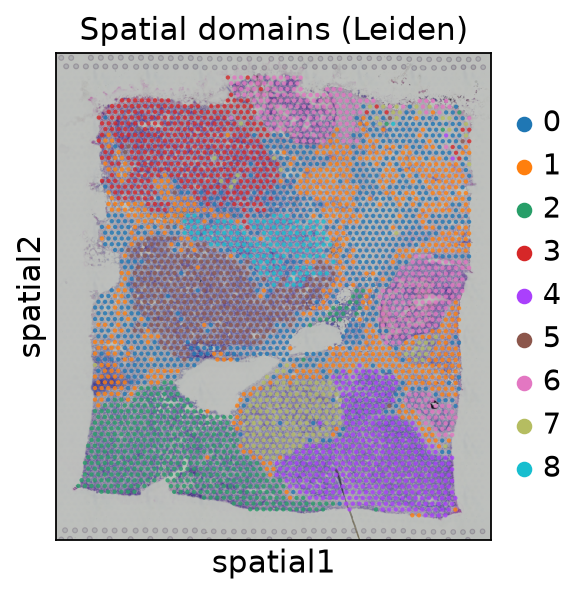

,tumor_score,stroma_score,immune_score,n_spots,dominant_program
cluster,,,,,
0,1.484,0.666,1.431,727,tumor
1,1.156,1.222,1.665,695,immune
2,1.610,0.527,0.870,467,tumor
3,1.521,0.102,1.057,409,tumor
4,1.708,0.250,0.811,403,tumor
5,1.520,0.009,1.164,373,tumor
6,1.508,-0.071,0.823,361,tumor
7,1.431,0.410,1.269,202,tumor
8,1.643,0.162,0.973,161,tumor


/tmp/ipykernel_1373480/4133554473.py:15: FutureWarning: Use `squidpy.pl.spatial_scatter` instead.
  sc.pl.spatial(spatial, color=list(programs), img_key="hires", cmap="magma", ncols=3)


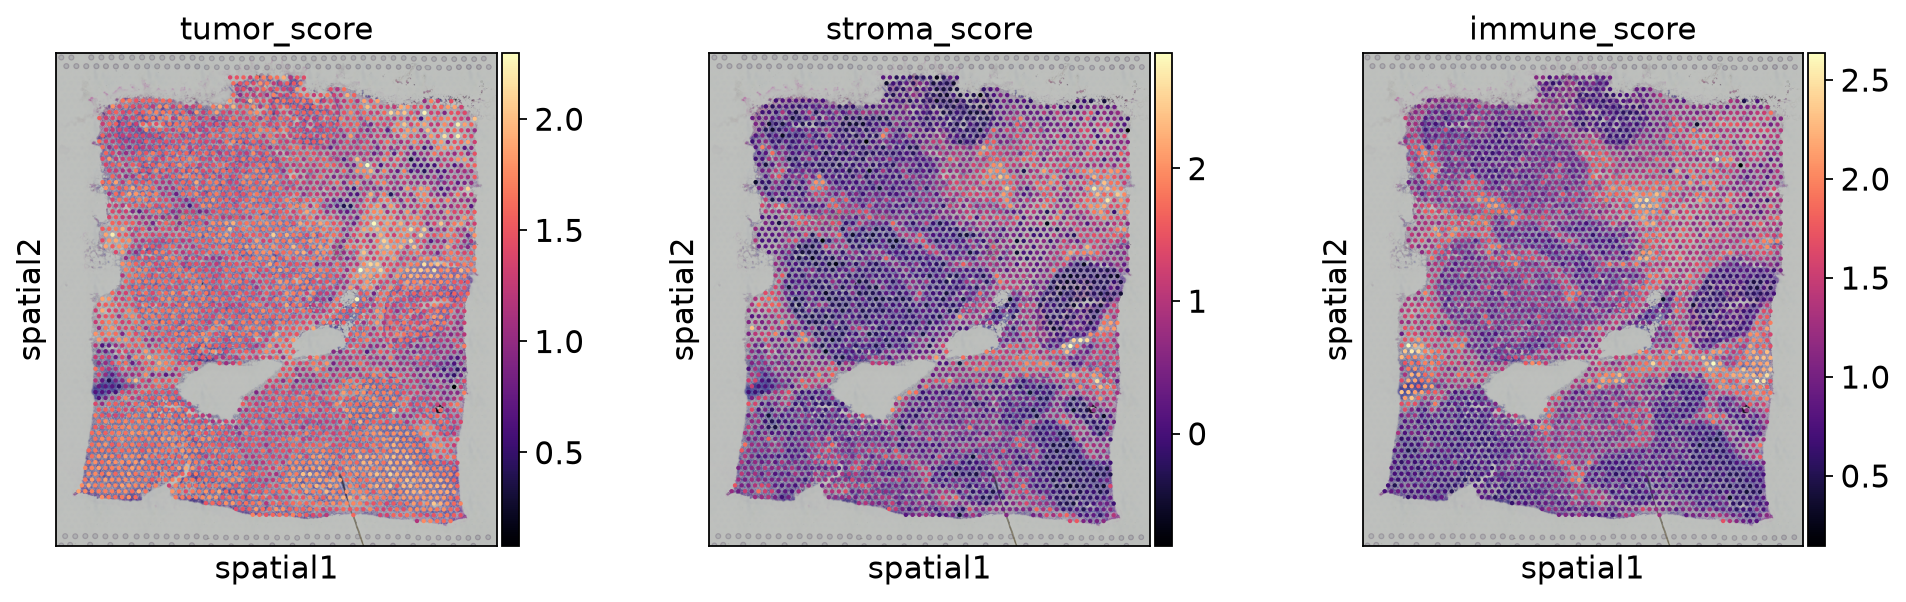

In [21]:
# H&E alone, then domains over the tissue
sc.pl.spatial(spatial, img_key="hires", title="H&E: V1_Breast_Cancer_Block_A_Section_1")
sc.pl.spatial(spatial, color="cluster", img_key="hires", alpha=0.8, title="Spatial domains (Leiden)")

# Name each domain: score tumor, stroma and immune programs per spot, then average per domain
programs = {"tumor_score":  ["EPCAM", "KRT8", "KRT18", "KRT19", "CDH1"],
            "stroma_score": ["COL1A1", "COL1A2", "COL3A1", "DCN", "LUM"],
            "immune_score": ["PTPRC", "CD74", "HLA-DRA", "CD3D", "IGKC", "MS4A1"]}
for name, genes in programs.items():
    sc.tl.score_genes(spatial, [g for g in genes if g in spatial.raw.var_names], score_name=name, use_raw=True)
dom_tab = spatial.obs.groupby("cluster", observed=True)[list(programs)].mean().round(3)
dom_tab["n_spots"] = spatial.obs["cluster"].value_counts().sort_index()
dom_tab["dominant_program"] = dom_tab[list(programs)].idxmax(axis=1).str.replace("_score", "")
display(dom_tab)
sc.pl.spatial(spatial, color=list(programs), img_key="hires", cmap="magma", ncols=3)

**TODO (interpretation):** Do the domains line up with recognizable tissue architecture (tumor nests, stroma, immune areas)?

*Your answer here.*Yes, the domains follow the tissue architecture visible on the H&E. The section consists of large, rounded, densely stained tumor nests separated by paler stromal bands, and the Leiden domains trace those boundaries closely. Seven domains (2–8; 161–467 spots each) have the highest tumor score (1.43–1.71) with near-zero stroma scores (−0.07 to 0.41), and each fills a separate nest: for example, domain 3 at the top left, domain 4 at the bottom right and domain 5 at the bottom center. Domain 1 (695 spots) is the only domain whose dominant program is not tumor. It has the highest stroma (1.22) and immune (1.67) scores and the lowest tumor score (1.16), and on the tissue it forms the bands running between and around the nests, so it is the stroma–immune compartment. Domain 0 (727 spots) is mixed, with a high tumor score (1.48) together with a high immune score (1.43), which points to tumor regions infiltrated by immune cells, or spots at tumor edges. Splitting the tumor into separate nest-specific domains, rather than one “tumor” domain, suggests the nests differ transcriptionally (for example in-situ versus invasive areas, or different subclones). One caveat: the tumor score is high in every domain because each 55 µm Visium spot averages several cells and keratin genes are broadly detected. The domains are therefore best read by their relative program scores, not as pure cell types.

## 2.4 · Spatially variable genes (Moran's I)
The spatial neighbor graph is built for you. **TODO:** compute Moran's I, list the top genes, and plot a few.

In [22]:
sq.gr.spatial_neighbors(spatial)

INFO     Creating graph using `None` transform and `1` libraries.                                                  


/tmp/ipykernel_1373480/2129188737.py:1: FutureWarning: Calling `spatial_neighbors` is deprecated and will be removed in squidpy v1.9.0. Use `spatial_neighbors_knn`, `spatial_neighbors_radius`, `spatial_neighbors_delaunay`, `spatial_neighbors_grid`, or `spatial_neighbors_from_builder` instead.
  sq.gr.spatial_neighbors(spatial)


Moran's I computed for 2000 highly variable genes; 854 significant at FDR < 0.05


,I,pval_norm_fdr_bh
MGP,0.8685,0.0
MALAT1,0.7625,0.0
CRISP3,0.7263,0.0
CPB1,0.7110,0.0
IGHG3,0.7038,0.0
IGLC2,0.7003,0.0
IGKC,0.6807,0.0
ALB,0.6679,0.0
IGHG1,0.6353,0.0
IGHG4,0.6315,0.0


/tmp/ipykernel_1373480/1901738688.py:10: FutureWarning: Use `squidpy.pl.spatial_scatter` instead.
  sc.pl.spatial(spatial, color=top3, img_key="hires", cmap="viridis", ncols=3, vmax="p99")


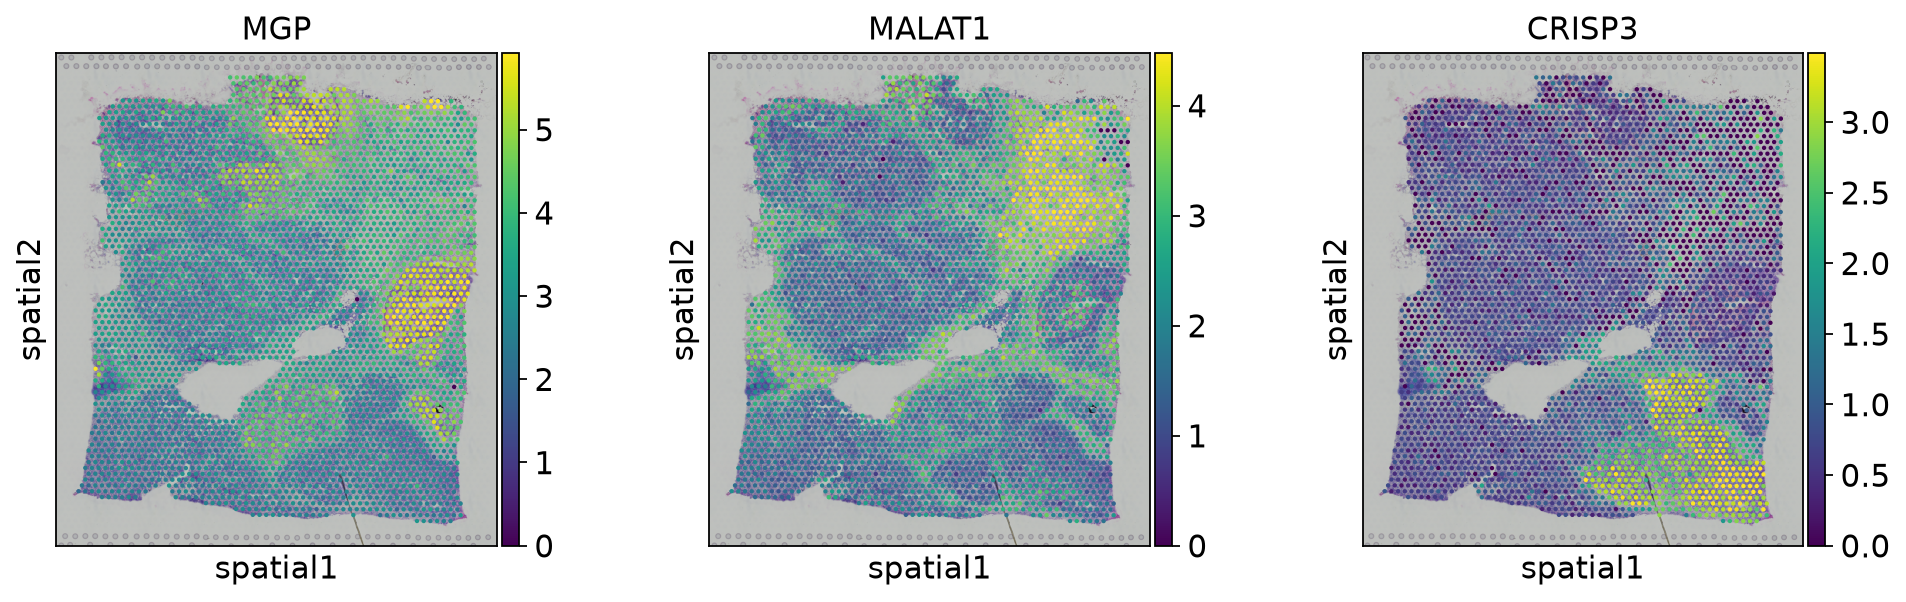

In [23]:
hvg = spatial.var_names[spatial.var["highly_variable"]]
sq.gr.spatial_autocorr(spatial, mode="moran", genes=hvg, n_jobs=4)
moran = spatial.uns["moranI"].sort_values("I", ascending=False)
top = moran.head(15)
print(f"Moran's I computed for {len(moran)} highly variable genes; "
      f"{(moran['pval_norm_fdr_bh'] < 0.05).sum()} significant at FDR < 0.05")
display(top[["I", "pval_norm_fdr_bh"]].round(4))

top3 = top.index[:3].tolist()
sc.pl.spatial(spatial, color=top3, img_key="hires", cmap="viridis", ncols=3, vmax="p99")

## 2.5 · Neighborhood enrichment
**TODO:** compute which domains sit next to each other more than chance, and read off any tumor-immune interface.

100%|██████████| 1000/1000 [00:01<00:00, 902.83/s]


,0,1,2,3,4,5,6,7,8
0,50.3,8.6,-24.5,-16.3,-21.8,-12.5,-16.2,-9.2,-7.8
1,8.6,54.9,-21.6,-17.9,-21.3,-17.0,-17.1,-8.9,-9.8
2,-24.5,-21.6,93.1,-19.0,-17.3,-18.6,-18.4,-12.3,-10.9
3,-16.3,-17.9,-19.0,86.6,-17.5,-16.2,-13.4,-7.7,-10.0
4,-21.8,-21.3,-17.3,-17.5,99.9,-16.5,-16.0,-8.5,-10.4
5,-12.5,-17.0,-18.6,-16.2,-16.5,86.9,-15.8,-11.4,-4.9
6,-16.2,-17.1,-18.4,-13.4,-16.0,-15.8,90.8,-9.4,-9.8
7,-9.2,-8.9,-12.3,-7.7,-8.5,-11.4,-9.4,78.1,-7.1
8,-7.8,-9.8,-10.9,-10.0,-10.4,-4.9,-9.8,-7.1,82.4


Top cross-domain contacts:


,domain_a,domain_b,z
0,0,1,8.6
47,5,8,-4.9
63,7,8,-7.1
30,3,7,-7.7
7,0,8,-7.8
38,4,7,-8.5
14,1,7,-8.9
6,0,7,-9.2


Contacts of the stroma-immune domain 1:


0     8.6
7    -8.9
8    -9.8
5   -17.0
6   -17.1
3   -17.9
4   -21.3
2   -21.6
Name: 1, dtype: float64

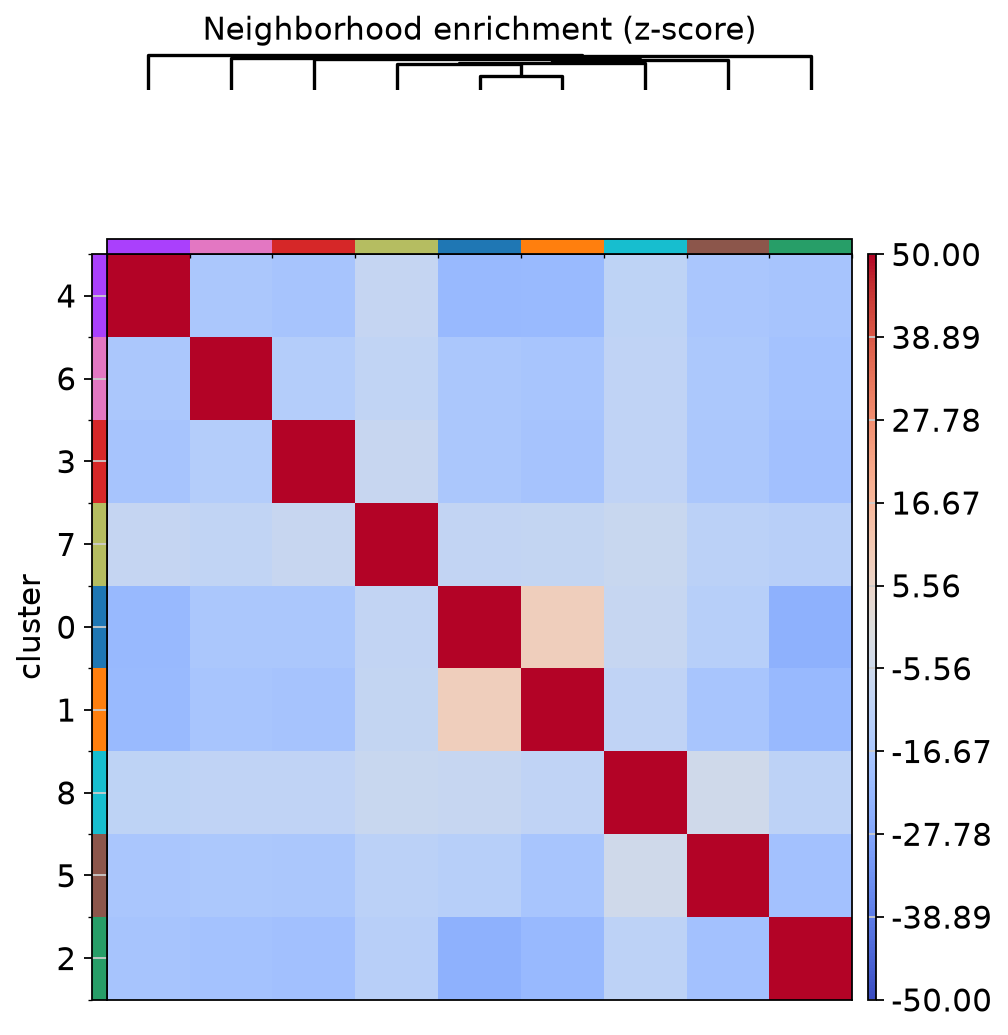

In [24]:
sq.gr.nhood_enrichment(spatial, cluster_key="cluster", seed=0)
sq.pl.nhood_enrichment(spatial, cluster_key="cluster", method="average",
                       cmap="coolwarm", vmin=-50, vmax=50, title="Neighborhood enrichment (z-score)")

cats = spatial.obs["cluster"].cat.categories
z = pd.DataFrame(spatial.uns["cluster_nhood_enrichment"]["zscore"], index=cats, columns=cats).round(1)
display(z)

# Strongest contacts between DIFFERENT domains (positive z = neighbors more often than chance)
pairs = (z.where(~np.eye(len(cats), dtype=bool)).stack()
           .reset_index().set_axis(["domain_a", "domain_b", "z"], axis=1))
pairs = pairs[pairs["domain_a"] < pairs["domain_b"]].sort_values("z", ascending=False)
print("Top cross-domain contacts:"); display(pairs.head(8))
print("Contacts of the stroma-immune domain 1:"); display(z.loc["1"].drop("1").sort_values(ascending=False))

**TODO (interpretation):** Which domains interface more than chance? Is there a tumor-immune boundary?

*Your answer here.*Every domain is strongly enriched for contacts with itself (diagonal z = 50–100), meaning each domain forms one spatially compact region rather than scattered spots, as expected for coherent tissue compartments. Only one pair of different domains touches more than chance: domain 0 and domain 1 (z = +8.6). All other cross-domain pairs are depleted (z = −4.9 to −24.5). Domain 1 is the stroma–immune compartment (highest stroma and immune scores, rich in immunoglobulin genes), and domain 0 is the mixed tumor-plus-immune domain (tumor score 1.48, immune score 1.43). So yes, there is a tumor–immune boundary, and it runs along the domain 0–domain 1 contact, where immune-infiltrated tumor meets the immune-rich stroma. By contrast, the tumor-nest domains 2–8 are depleted next to domain 1 (z = −8.9 to −21.6) and next to each other. The nests are therefore compact, separated blocks whose cores have little direct contact with the immune compartment, a pattern consistent with immune-excluded tumor cores, where immune cells are held at the edge. One caveat is that this test only counts adjacency between Leiden labels on the spot grid: it cannot resolve individual cells within a 55 µm spot, and its result depends on how the domains were drawn

## 2.6 · Locate your target in the tissue
**TODO:** color the tissue by the same target gene and describe where it sits.

/tmp/ipykernel_1373480/1039802644.py:3: FutureWarning: Use `squidpy.pl.spatial_scatter` instead.
  sc.pl.spatial(spatial, color=[TARGET, "cluster"], img_key="hires", use_raw=True,


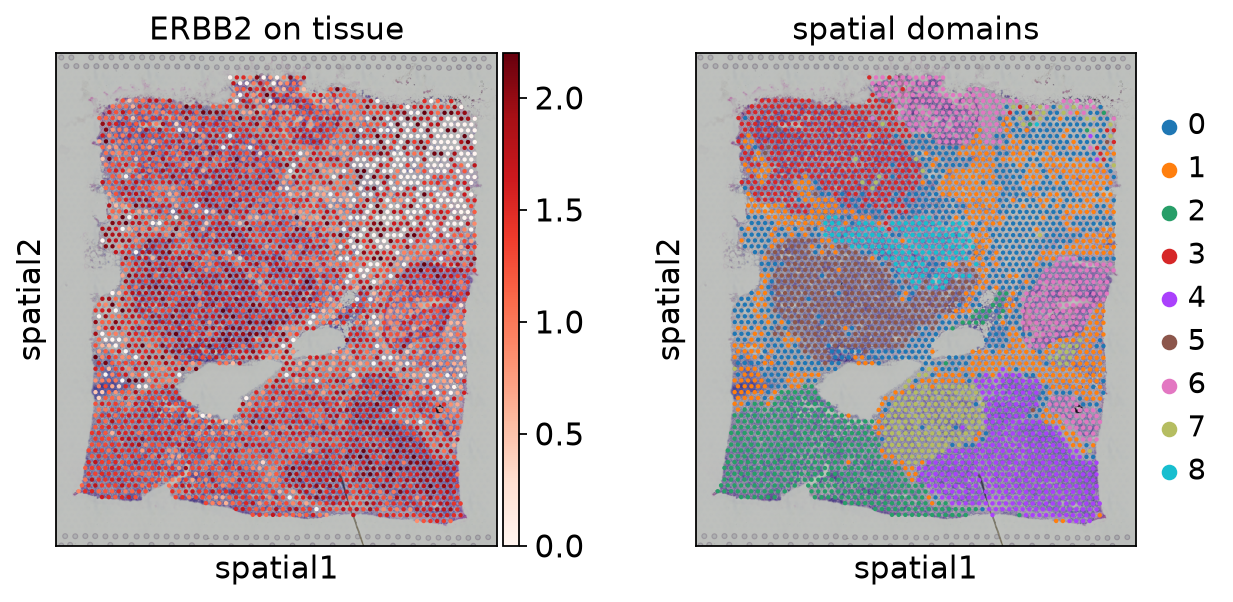

,n_spots,mean_log_expr,pct_spots_pos,dominant_program
cluster,,,,
5,373,1.650,99.464,tumor
4,403,1.640,99.504,tumor
8,161,1.534,100.000,tumor
7,202,1.411,96.535,tumor
3,409,1.381,97.311,tumor
2,467,1.355,99.143,tumor
6,361,1.316,96.122,tumor
0,727,1.217,80.330,tumor
1,695,0.978,83.453,immune


/tmp/ipykernel_1373480/1039802644.py:23: FutureWarning: Use `squidpy.pl.spatial_scatter` instead.
  sc.pl.spatial(spatial, color="zone", img_key="hires", title="Tumor core vs margin (graph-based)")


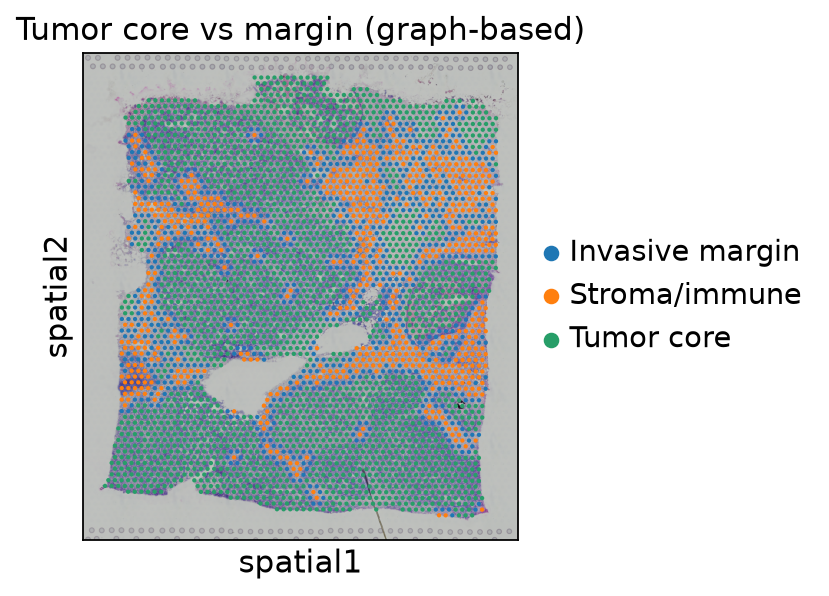

,n_spots,mean_log_expr,pct_spots_pos
zone,,,
Invasive margin,815,1.266,86.258
Stroma/immune,695,0.978,83.453
Tumor core,2288,1.457,96.897


core vs margin p = 6.95e-12 | tumor (core+margin) vs stroma p = 0.00e+00
ERBB2 Moran's I = 0.237


In [25]:
TARGET = "ERBB2"
assert TARGET in spatial.raw.var_names, f"{TARGET} not in this section"
sc.pl.spatial(spatial, color=[TARGET, "cluster"], img_key="hires", use_raw=True,
              cmap="Reds", vmax="p99", ncols=2, title=[f"{TARGET} on tissue", "spatial domains"])

t = spatial.raw[:, TARGET].X
t = t.toarray().ravel() if hasattr(t, "toarray") else np.asarray(t).ravel()
spatial.obs[f"{TARGET}_expr"] = t

# 1) ERBB2 per domain
by_dom = (spatial.obs.groupby("cluster", observed=True)[f"{TARGET}_expr"]
          .agg(n_spots="size", mean_log_expr="mean", pct_spots_pos=lambda v: 100 * (v > 0).mean())
          .join(dom_tab["dominant_program"]).sort_values("mean_log_expr", ascending=False).round(3))
display(by_dom)

# 2) Core vs margin: tumor spots touching the stroma-immune domain = margin; fully surrounded = core
tumor_domains = dom_tab.index[dom_tab["dominant_program"] == "tumor"].astype(str).tolist()
is_tumor = spatial.obs["cluster"].astype(str).isin(tumor_domains).values
A = spatial.obsp["spatial_connectivities"]
frac_tumor_nbrs = np.asarray(A @ is_tumor.astype(float)).ravel() / np.maximum(np.asarray(A.sum(1)).ravel(), 1)
spatial.obs["zone"] = pd.Categorical(np.select(
    [is_tumor & (frac_tumor_nbrs == 1), is_tumor], ["Tumor core", "Invasive margin"], "Stroma/immune"))
sc.pl.spatial(spatial, color="zone", img_key="hires", title="Tumor core vs margin (graph-based)")

zone_tab = (spatial.obs.groupby("zone", observed=True)[f"{TARGET}_expr"]
            .agg(n_spots="size", mean_log_expr="mean", pct_spots_pos=lambda v: 100 * (v > 0).mean()).round(3))
display(zone_tab)

from scipy.stats import mannwhitneyu
core = t[spatial.obs["zone"] == "Tumor core"]; margin = t[spatial.obs["zone"] == "Invasive margin"]
stroma = t[spatial.obs["zone"] == "Stroma/immune"]
print(f"core vs margin p = {mannwhitneyu(core, margin).pvalue:.2e} | "
      f"tumor (core+margin) vs stroma p = {mannwhitneyu(np.r_[core, margin], stroma).pvalue:.2e}")

mi = sq.gr.spatial_autocorr(spatial, mode="moran", genes=[TARGET], copy=True)
print(f"{TARGET} Moran's I = {mi['I'].iloc[0]:.3f}")

**TODO (interpretation):** Where does your target sit: tumor core, invasive margin, or an immune niche?

*Your answer here.*ERBB2 sits in the tumor cores. It is highest in the compact tumor-nest domains, 5, 4 and 8 (mean log-expression 1.53–1.65, with 99.5–100% of spots positive), followed by the other nest domains 7, 3, 2 and 6 (1.32–1.41). It is lower in the mixed tumor–immune domain 0 (1.22; 80% positive) and lowest in the stroma–immune domain 1 (0.98). Using the spatial graph to divide tumor spots into core (all neighbors tumor) and invasive margin (touching stroma–immune spots), ERBB2 forms a clear gradient: tumor core 1.457 (96.9% of 2,288 spots) > invasive margin 1.266 (86.3% of 815) > stroma/immune 0.978 (83.5% of 695). Core is higher than margin (Mann–Whitney p = 7 × 10⁻¹²), and tumor is higher than stroma (p < 10⁻³⁰⁰, below floating-point precision). Its Moran’s I (0.24) is far below the nest-specific genes (MGP 0.87), meaning ERBB2 is not confined to one nest but broadly raised across the whole tumor, as expected in a HER2-positive cancer. That matches Part 1, where ERBB2 was a tumor-cell gene that is very high in HER2-amplified patients. ERBB2 is still detected in most stroma spots, because each 55 µm spot mixes several cells and tumor RNA spills into neighboring spots, so its “stromal” signal is partly contamination rather than stromal expression. The target is therefore concentrated in the tumor core, the region that the neighborhood analysis showed is largely immune-excluded, with lower but substantial expression at the margin where tumor meets the immune compartment.

---
# PART 3 · Connect it (your report)

Write a 4–5 page report (separate PDF) that ties the two views together:

- Which cell types express your target (Part 1), and where those cells sit in the tumor (Part 2).
- Your integration choice, justified with the scores.
- The spatial context and why it matters clinically (a target at the invasive margin versus shut inside the core).
- The limitations of each analysis: donor count and label resolution (single-cell); spot resolution, panel, and segmentation (spatial).

Then **Kernel → Restart & Run All**, commit this notebook and your report to your biot6900 repo, and post the repo link on Canvas.